## Выбор целевой переменной, даты и группы

Для проведения разведочного анализа данных (EDA) выбраны следующие столбцы из `data/processed/clean.parquet` (имена сохраняются без изменений для последующего использования в лабораторной работе 3):

- **Целевая переменная:** `price` (цена игры).
- **Столбец даты:** `release_date` (дата выхода игры в Steam).
- **Столбец группы:** `genres` (жанр игры).

### Обоснование выбора

1. **Почему `price` выбрана целевой переменной:**

   `price` — количественная переменная, отражающая стоимость игры. Она позволяет исследовать распределение цен, рассчитывать основные статистические показатели (среднее, медиану, квартили), а также выявлять необычно высокие и низкие значения. Несмотря на наличие пропусков, столбец содержит достаточное количество числовых значений для проведения анализа. Пропущенные значения учитываются отдельно и не включаются в расчёт статистических показателей.

2. **Почему период агрегации равен месяцу:**

   Временной ряд охватывает несколько лет релизов. При агрегации по дням или неделям график становится более шумным из-за неравномерного распределения дат выхода игр. Выбор **месяца** позволяет сгладить локальные колебания и проследить изменение цен на игры с течением времени, сохраняя при этом пустые периоды без искусственного сглаживания.

3. **Почему значения группы (`genres`) повторяются:**

   Жанр является категориальным признаком с ограниченным набором значений. Поскольку на платформе выпускаются десятки тысяч игр, многие из них относятся к одним и тем же жанрам (например, *Indie*, *Action*, *Adventure*, *RPG*). Это позволяет рассчитывать групповые агрегаты (медиану, среднее, количество записей и долю пропусков), а также объединять редкие категории (доля менее 1%) в группу «прочие».

## Шаг 3. Распределение целевой переменной

In [19]:
import sys
from pathlib import Path
import pandas as pd

# Добавляем корень проекта в sys.path, чтобы импортировать src
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.eda import get_target_summary

In [20]:
df = pd.read_parquet(
    project_root / "data" / "processed" / "clean.parquet"
)

print(df.shape)

TARGET_COL = "price"
DATE_COL = "release_date"
GROUP_COL = "genres"

table_1 = get_target_summary(df, TARGET_COL)
table_1

(125365, 39)


,Показатель,Значение
0,Число наблюдений,125365
1,Число пропусков,0
2,Минимум,0.0
3,Первый квартиль,0.59
4,Медиана,2.39
5,Среднее,4.22
6,Третий квартиль,5.39
7,Максимум,59.95
8,Скошенность,Вправо (положительная)


### Вывод по Шагу 3 (Таблица 1)
В выборке содержится 125 365 наблюдения без пропусков. Распределение целевой переменной `price` имеет выраженную **правостороннюю (положительную) скошенность**: пропусков записей нет, типичное значение (медиана) составляет **2.39**, среднее смещено вправо до **4.22** за счёт экстремальных значений вплоть до максимума **59.95**, а минимум равен **0**.

## Шаг 4. Динамика по датам

In [21]:
from importlib import reload
import src.eda

reload(src.eda)
from src.eda import get_date_dynamics

In [22]:
from src.eda import get_date_dynamics

DATE_COL = "release_date"
TARGET_COL = "price"

date_dynamics = get_date_dynamics(df, DATE_COL, TARGET_COL)

print(f"Всего периодов (месяцев) в динамике: {len(date_dynamics)}")

mid_idx = len(date_dynamics) // 2

table_2 = pd.concat([
    date_dynamics.head(3),
    date_dynamics.iloc[mid_idx - 1 : mid_idx + 2],
    date_dynamics[
        date_dynamics["Период"].isin(["2025-09", "2025-10", "2025-11"])
    ]
]).drop_duplicates().reset_index(drop=True)

table_2 = table_2.fillna(0)

display(table_2)


Всего периодов (месяцев) в динамике: 355


,Период,Число записей,Медиана цели,Среднее цели
0,1997-06,1,2.49,2.49
1,1997-07,0,0.00,0.00
2,1997-08,0,0.00,0.00
3,2012-02,24,2.19,2.80
4,2012-03,26,3.29,3.69
5,2012-04,25,2.99,3.20
6,2025-09,2107,2.49,4.70
7,2025-10,2558,2.79,4.69
8,2025-11,2403,4.24,5.99


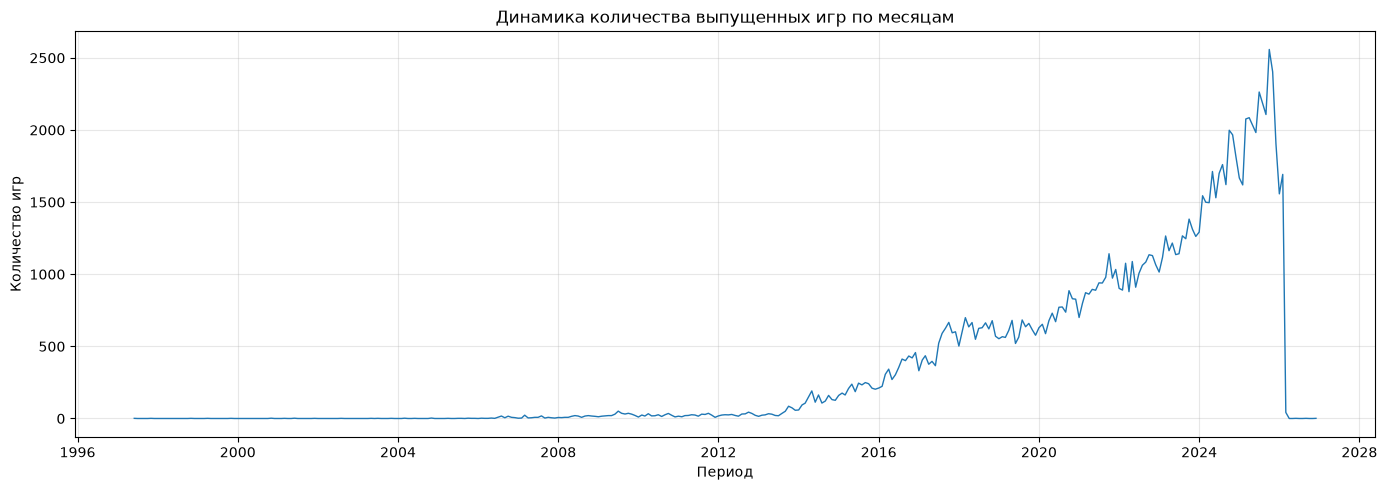

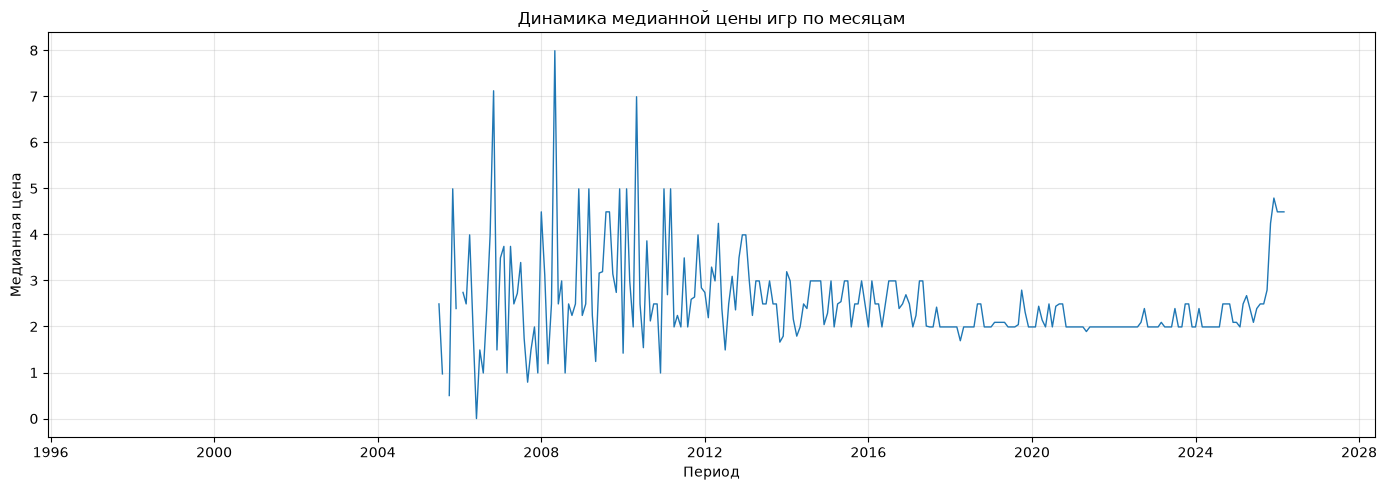

In [23]:
import matplotlib.pyplot as plt
import pandas as pd

# Преобразуем период в формат даты для построения графика
plot_data = date_dynamics.copy()
plot_data["Период"] = pd.to_datetime(plot_data["Период"])

# График 1. Количество записей по месяцам
plt.figure(figsize=(14, 5))
plt.plot(
    plot_data["Период"],
    plot_data["Число записей"],
    linewidth=1
)

plt.title("Динамика количества выпущенных игр по месяцам")
plt.xlabel("Период")
plt.ylabel("Количество игр")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# График 2. Медиана цены по месяцам
plt.figure(figsize=(14, 5))
plt.plot(
    plot_data["Период"],
    plot_data["Медиана цели"],
    linewidth=1
)

plt.title("Динамика медианной цены игр по месяцам")
plt.xlabel("Период")
plt.ylabel("Медианная цена")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

В начале временного ряда (июнь–август 1997 года) количество записей было небольшим: в июне зарегистрирована одна игра, а в июле и августе записи отсутствовали. В середине ряда (февраль–апрель 2012 года) количество выпущенных игр составляло от 24 до 26 в месяц, а медианная цена находилась в диапазоне от 2,19 до 3,29. Осенью 2025 года наблюдается значительно большее количество записей: от 2107 до 2558 игр в месяц. При этом медианная цена увеличилась с 2,49 в сентябре до 4,24 в ноябре. Таким образом, в выбранных периодах заметно увеличение количества записей и рост медианной цены к концу осени 2025 года.По графику динамики количества выпущенных игр наблюдается общий рост числа записей с течением времени. Особенно заметное увеличение начинается после 2012 года, а в период 2024–2026 годов количество выпусков достигает наиболее высоких значений. При этом в конце временного ряда наблюдается резкое снижение показателя, которое требует дополнительной проверки данных.

Динамика медианной цены отличается от динамики количества игр. В период с 2005 по 2012 год наблюдаются значительные колебания цен. В последующие годы показатель становится более стабильным и преимущественно находится в диапазоне 2–3. В 2025–2026 годах заметно повышение медианной цены примерно до 4–5.

Таким образом, количество выпускаемых игр в целом увеличивалось, тогда как медианная цена изменялась менее равномерно. Рост числа выпусков не всегда сопровождался аналогичным изменением типичной цены игры.

## Шаг 5. Агрегаты и сводная таблица

In [24]:
from importlib import reload
import src.eda

reload(src.eda)

from src.eda import get_group_aggregates

# Таблица 3 — агрегаты по группам
group_aggregates = get_group_aggregates(
    df, GROUP_COL, TARGET_COL
)

display(group_aggregates)

,genres,Число записей,Медиана,Среднее,"Доля пропусков, %"
2566,"Single-player,Family Sharing",23778,2.99,4.86,0.0
10548,"Single-player,Steam Achievements,Family Sharing",10077,1.99,3.41,0.0
14018,Не указано,8921,0.00,0.88,0.0
1768,Single-player,4550,0.00,0.09,0.0
12740,"Single-player,Steam Achievements,Steam Cloud,F...",4291,3.39,4.63,0.0
...,...,...,...,...,...
12,"Camera Comfort,Color Alternatives,Mouse Only O...",1,0.99,0.99,0.0
13,"Camera Comfort,Custom Volume Controls,Adjustab...",1,24.99,24.99,0.0
14,"Camera Comfort,Mouse Only Option,Playable with...",1,0.69,0.69,0.0
15,"Camera Comfort,Playable without Timed Input,Sa...",1,1.99,1.99,0.0


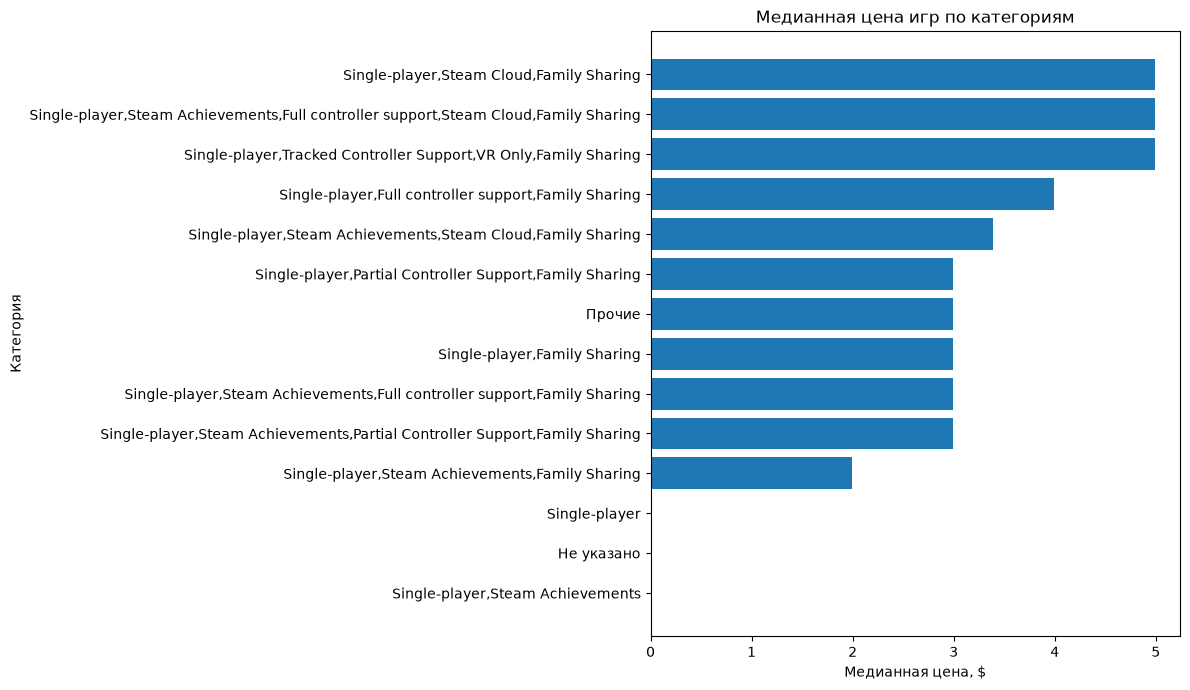

Всего категорий: 14019
Редких категорий: 14006


In [25]:
import matplotlib.pyplot as plt

# Порог редкой категории — менее 1%
total_records = group_aggregates["Число записей"].sum()

rare_groups = group_aggregates[
    group_aggregates["Число записей"] / total_records < 0.01
]["genres"]

# Подготовка данных
plot_df = df[["genres", "price"]].copy()

plot_df["genres"] = plot_df["genres"].fillna("Не указано")
plot_df["price"] = pd.to_numeric(plot_df["price"], errors="coerce")

# Объединение редких категорий
plot_df.loc[
    plot_df["genres"].isin(rare_groups),
    "genres"
] = "Прочие"

# Пересчёт медианы после объединения
plot_data = (
    plot_df.groupby("genres", observed=True)["price"]
    .median()
    .sort_values(ascending=False)
)

# Отображение 15 крупнейших категорий
plot_data = plot_data.head(15).sort_values()

plt.figure(figsize=(12, 7))
plt.barh(plot_data.index, plot_data.values)

plt.xlabel("Медианная цена, $")
plt.ylabel("Категория")
plt.title("Медианная цена игр по категориям")

plt.tight_layout()
plt.show()

print("Всего категорий:", len(group_aggregates))
print("Редких категорий:", len(rare_groups))

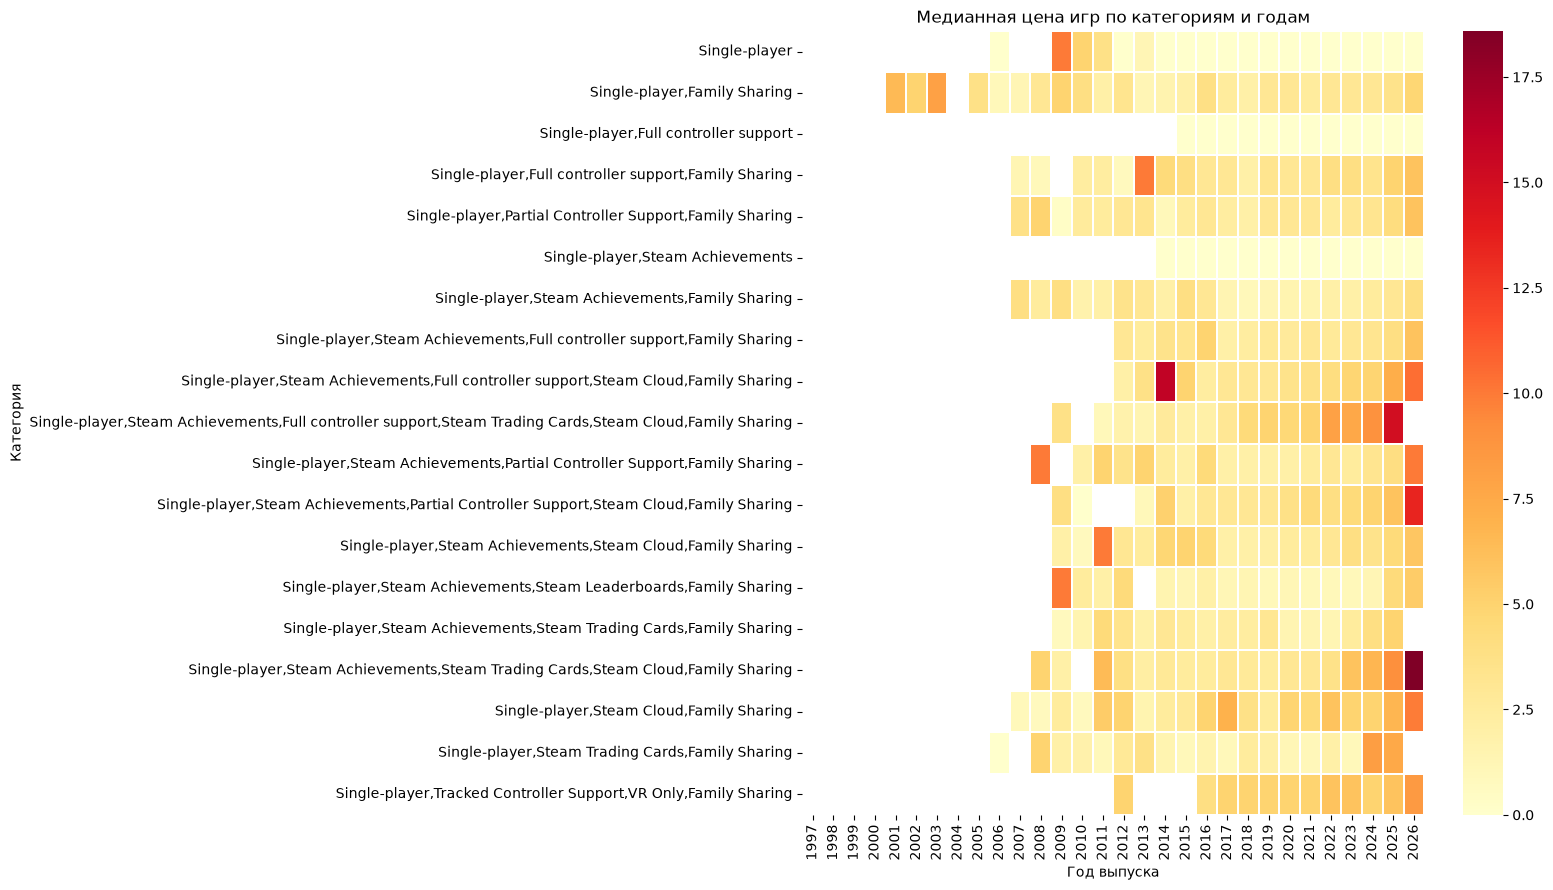

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

# Выбираем 20 наиболее многочисленных категорий
top_categories = group_aggregates.head(20)["genres"]

pivot_table = df.pivot_table(
    index="genres",
    columns=df["release_date"].dt.year,
    values="price",
    aggfunc="median"
)

# Оставляем их в сводной таблице
heatmap_data = pivot_table.loc[
    pivot_table.index.isin(top_categories)
]

plt.figure(figsize=(16, 9))

sns.heatmap(
    heatmap_data,
    cmap="YlOrRd",
    annot=False,
    linewidths=0.3
)

plt.title("Медианная цена игр по категориям и годам")
plt.xlabel("Год выпуска")
plt.ylabel("Категория")

plt.tight_layout()
plt.show()

In [28]:
from importlib import reload
import src.eda

reload(src.eda)

from src.eda import get_group_period_pivot

# Создаём полную сводную таблицу
pivot_table = get_group_period_pivot(
    df, GROUP_COL, TARGET_COL, DATE_COL
)

# Выбираем 20 наиболее многочисленных категорий
top_categories = group_aggregates.head(20)["genres"]

# Формируем сокращённую сводную таблицу
pivot_table = pivot_table.loc[
    pivot_table.index.isin(top_categories)
]

display(pivot_table)

Год,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
genres,,,,,,,,,,,,,,,,,,,,,
Single-player,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,...,0.000,0.00,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
"Single-player,Family Sharing",NaN,NaN,NaN,NaN,6.49,4.94,7.99,NaN,3.74,0.99,...,2.490,1.99,2.990,2.990,2.540,2.990,2.990,2.990,3.490,4.790
"Single-player,Full controller support",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.000,0.00,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
"Single-player,Full controller support,Family Sharing",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.990,1.99,3.340,2.990,2.990,3.990,3.940,3.410,4.990,5.990
"Single-player,Partial Controller Support,Family Sharing",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.390,1.99,2.990,2.990,2.990,2.495,2.990,3.265,4.190,5.990
"Single-player,Steam Achievements",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.000,0.00,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
"Single-player,Steam Achievements,Family Sharing",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.390,0.99,1.240,1.490,1.490,1.990,1.990,2.490,2.990,3.990
"Single-player,Steam Achievements,Full controller support,Family Sharing",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.990,2.39,2.865,2.640,2.990,2.690,2.990,3.240,3.990,5.965
"Single-player,Steam Achievements,Full controller support,Steam Cloud,Family Sharing",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.990,2.99,2.990,3.490,3.740,4.130,4.830,4.890,7.240,10.390


## Вывод по шагу 5. Агрегаты и сводная таблица
В ходе анализа были рассчитаны количество записей, медианная и средняя цена, а также доля пропусков для каждой категории. Всего было выделено 14 019 категорий, представляющих различные комбинации характеристик игр в Steam.

Наибольшее количество записей относится к категории Single-player, Family Sharing — 23 778 игр. Её медианная цена составляет 2,99 $, средняя — 4,86 $. Следующая по численности категория Single-player, Steam Achievements, Family Sharing включает 10 077 записей, а медианная и средняя цены составляют 1,99 $ и 3,41 $ соответственно. Это показывает, что стоимость игр различается в зависимости от набора характеристик.

Для построения столбчатой диаграммы редкие категории с долей менее 1% были объединены в группу «Прочие». Диаграмма показывает различия в медианной стоимости игр между наиболее распространёнными категориями. Наиболее высокие значения медианной цены достигают примерно 5 $, тогда как у некоторых категорий медианная цена равна нулю.

Также была сформирована сводная таблица, отражающая изменение медианной цены по годам выпуска игр. На её основе построена тепловая карта. Она показывает, что для многих категорий в ранние годы отсутствуют данные, а в более поздние периоды значения встречаются чаще. В отдельных категориях заметно увеличение медианной цены в последние годы. Пустые ячейки обозначают отсутствие записей для соответствующей категории и года.

Таким образом, группировка и расчёт агрегатов позволили выявить наиболее распространённые категории, сравнить стоимость игр и проследить её изменения по годам. Полученные результаты показывают различия в ценах между категориями и помогают лучше понять структуру исследуемого набора данных.

## Шаг 6. Аномалии

In [31]:
import importlib
import src.eda
importlib.reload(src.eda)
from src.eda import detect_anomalies

anom_res = detect_anomalies(df, TARGET_COL)

total_n = len(df)
c_iqr = anom_res["count_iqr"]
c_z = anom_res["count_z"]
c_both = anom_res["count_both"]

mask_iqr = anom_res["mask_iqr"]
mask_z = anom_res["mask_z"]

table_4 = pd.DataFrame([
    {
        "Правило": "Межквартильный размах",
        "Число отмеченных": c_iqr,
        "Доля": f"{c_iqr / total_n * 100:.2f}%",
        "Совпало со вторым": c_both,
    },
    {
        "Правило": "Второе правило (|z| > 3)",
        "Число отмеченных": c_z,
        "Доля": f"{c_z / total_n * 100:.2f}%",
        "Совпало со вторым": c_both,
    },
    {
        "Правило": "Пересечение",
        "Число отмеченных": c_both,
        "Доля": f"{c_both / total_n * 100:.2f}%",
        "Совпало со вторым": "—",
    },
])

table_4

[Шаг 6 | Аномалии по 'price'] Правило 1 (IQR, границы [-6.61; 12.59]): 8907 строк; Правило 2 (|z| > 3, порог > 21.27): 1951 строк; Пересечение: 1951 строк.


,Правило,Число отмеченных,Доля,Совпало со вторым
0,Межквартильный размах,8907,7.10%,1951
1,Второе правило (|z| > 3),1951,1.56%,1951
2,Пересечение,1951,1.56%,—


Краткие выводы по результатам Шага 6 для признака `price`:

* **Правило IQR (межквартильный размах):** отметило **8 907 игр (7.10%)** с ценой выше **$12.59**. Правило мягко реагирует на правостороннюю скошенность цен (большинство игр дешевые, но есть дорогие издания).
* **Z-оценка ($\vert{}z\vert{} > 3$):** выделила **1 951 игру (1.56%)** с ценой выше **$21.27** (настоящие ценовые экстремумы и бандлы).
* **Пересечение (1 951 строк):** абсолютно все аномалии по Z-оценке вошли в список IQR (полное совпадение второго множества с пересечением).
* **Итог:** Разница в числе строк объясняется разной строгостью методов на скошенном ряду. Исходный файл `clean.parquet` не изменён — для дальнейших графиков используются только логические маски.

## Шаг 7. Цикл и numpy

In [32]:
from src.eda import mean_loop, mean_numpy, median_seconds

# Берем значения целевого признака
values = df[TARGET_COL].values
n_values = len(values)

# Сверяем результаты перед замером времени
res_loop = mean_loop(values)
res_numpy = mean_numpy(values)
print(f"Результат (цикл): {res_loop:.4f}")
print(f"Результат (numpy): {res_numpy:.4f}")
assert abs(res_loop - res_numpy) < 1e-5, "Результаты расхожатся! Сравнение времени отменено."

# Замеры времени (3 повтора, берем медиану)
time_loop = median_seconds(mean_loop, values)
time_numpy = median_seconds(mean_numpy, values)
ratio = time_loop / time_numpy if time_numpy > 0 else float('inf')

# Формируем Таблицу 5
table_5 = pd.DataFrame([
    {
        "Способ": "Цикл Python",
        "Медиана времени, с": round(time_loop, 6),
        "Значение метрики": round(res_loop, 4),
    },
    {
        "Способ": "numpy",
        "Медиана времени, с": round(time_numpy, 6),
        "Значение метрики": round(res_numpy, 4),
    },
    {
        "Способ": "Отношение цикл / numpy",
        "Медиана времени, с": round(ratio, 2),
        "Значение метрики": "—",
    },
    {
        "Способ": "Число значений",
        "Медиана времени, с": n_values,
        "Значение метрики": "—",
    },
])

table_5

ImportError: cannot import name 'mean_loop' from 'src.eda' (d:\Python_Data_lab1\src\eda.py)